In [52]:
import httpx
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path

In [53]:
resp = httpx.get("https://www.wallpapergeeks.com/wp-content/uploads/2014/03/Nature_107.jpg")
Path("data.jpg").write_bytes(resp.content)

508360

(1333, 2000)

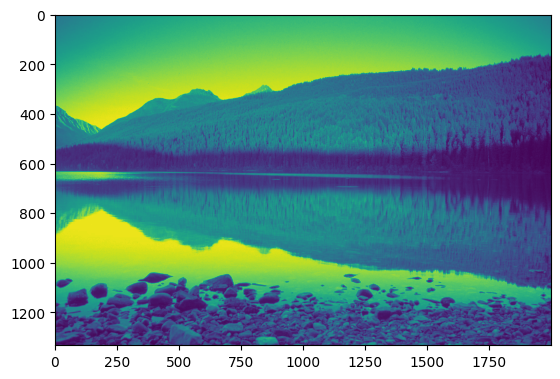

In [54]:
from matplotlib.image import imread

A = imread("data.jpg")
X = np.mean(A, -1)
img = plt.imshow(X)
X.shape

In [55]:
U,s,Vt = np.linalg.svd(X, full_matrices=False)

In [56]:
X.shape, U.shape, s.shape, Vt.shape

((1333, 2000), (1333, 1333), (1333,), (1333, 2000))

In [57]:
S = np.diag(s)

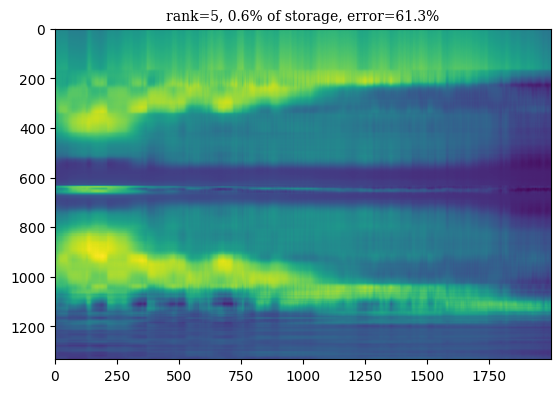

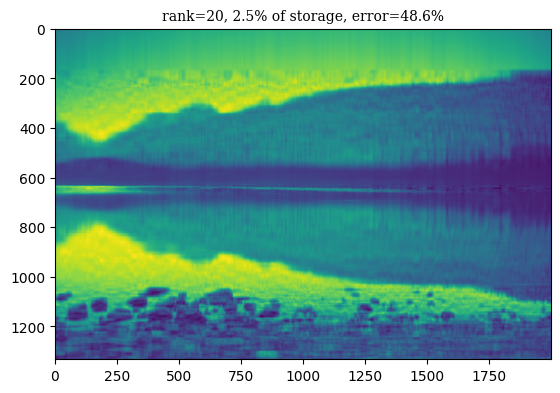

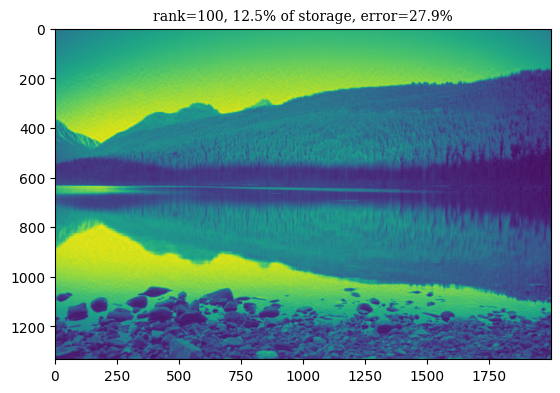

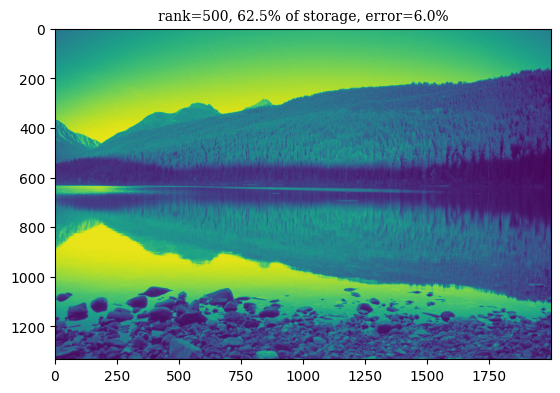

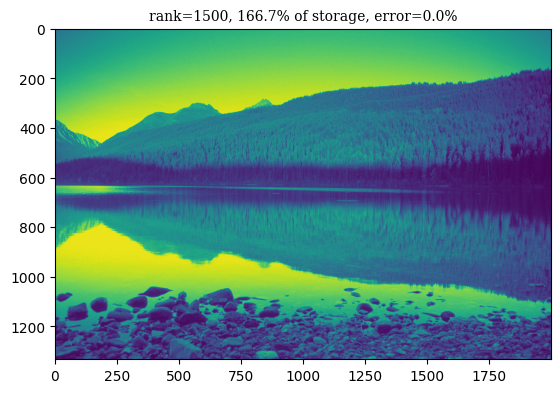

In [ ]:
for r in [5, 20, 100, 500, 1500]:

    Ur = U[:,:r]
    Vtr = Vt[:r,:]

    storage = (Ur.size + Vtr.size +r)/X.size
    error = np.sum(s[r:])/np.sum(s)

    Xapprox = Ur @ S[:r,:r] @ Vtr

    plt.title(f"rank={r}, {storage*100:3.1f}% of storage, error={error*100:3.1f}%", 
              family='serif', 
              size=10, 
              weight='ultralight')
    
    plt.imshow(Xapprox)
    plt.show()

    

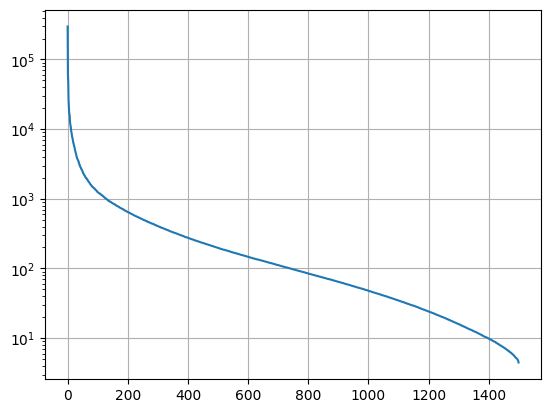

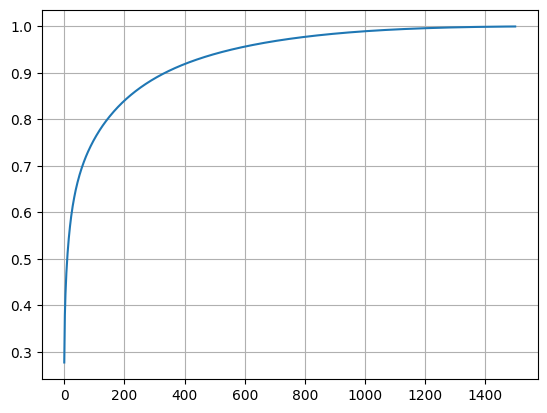

In [9]:
plt.subplots()
plt.semilogy(s)
plt.grid()

plt.subplots()
plt.plot(np.cumsum(s)/np.sum(s))
plt.grid()

In [ ]:
s.shape